# Text Mining

#### Group Members:
- Afonso Fernandes / 20241710
- Lourenço Lima / 20241711
- Simão Costa / 2024
- Gustavo Franco / 2024

<a id="1."></a>    

## **1. Abstract**
xxx


<a id="2."></a>    

## **2. Introduction**
Music lyrics provide a valuable source of information for exploring musical genres and emotional expression. This project applies **Natural Language Processing** techniques to investigate whether **lyrical patterns** can help **distinguish genres** and reveal differences in sentiment.

The analysis has two main objectives: to **develop and evaluate models** that predict a song’s genre from its lyrics, and to **explore sentiment within and across genres**. Through data exploration, text preprocessing and comparisons of different text representations and modelling approaches, we aim to identify meaningful patterns while critically discussing the limitations of our methods.

    
<a id="3."></a>

## **2. Project Objectives**

<a id="3.1."></a>    

##### **1.1. Main goal:** - Apply **Natural Language Processing techniques** to predict musical genres from song lyrics and investigate the **sentiment patterns within and across genres**.

<a id="3.2."></a>    

##### **1.2. Particular goals:** - **Data Exploration:** Examine genre distributions, lyrical characteristics and data quality to identify patterns and potential issues.
- **Text Preprocessing:** Prepare song lyrics for analysis, justifying decisions regarding section labels, tokenization, stopwords and text normalization.
- **Text Representation:** Compare approaches for transforming lyrics into numerical features suitable for predictive modelling.
- **Genre Classification:** Develop, optimize and compare classification models using appropriate validation strategies and evaluation metrics.
- **Sentiment Analysis:** Analyse the emotional polarity of lyrics and investigate differences within and across musical genres.
- **Critical Interpretation:** Discuss the main findings, classification errors and methodological limitations, identifying opportunities for future improvement.

## **4. Data Loading and Initial Inspection**

We first load the training and dataset and inspect their structure, data types and missing values. The training dataset includes the target variable, `tag`, whereas the test dataset does not. The sample submission defines the expected format for the final predictions.

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
train_df = pd.read_csv( "datasets/train.csv" )
display(train_df.shape)

(134967, 8)

In [4]:
train_df.head(10)

,title,tag,artist,year,views,features,lyrics,id
0,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...,535805
1,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...,7519483
2,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...,4892808
3,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...,1584150
4,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...,7639050
5,Right There,rap,HoustonBlake,2015,61,{},Oh yeah\nOh yeah yeah yeah\nOh yeah\nRight the...,2276689
6,Lost,pop,Della Marie,2016,44,{},Sick to my stomach\nGot something up in my blo...,3312430
7,King Cap,rap,YRM Bear,2018,1,"{""Corey J.""}",[YRM Bear]\n\nSlide through the curb like toos...,7749704
8,Respec my Mynyn,rap,Lil_Sauce_Goblin,2019,48,{},GRUFACE BABII\nGive banana if he like it he go...,4260038
9,Old Friend,pop,Tom Robinson,1984,19,{},These will be the days\nThat we'll remember in...,5659885


We can already observe that some years may be wrongly inside the data. The lyrcis will also need to be cleaned. 

In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134967 entries, 0 to 134966
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   title     134965 non-null  object
 1   tag       134967 non-null  object
 2   artist    134967 non-null  object
 3   year      134967 non-null  int64 
 4   views     134967 non-null  int64 
 5   features  134967 non-null  object
 6   lyrics    134967 non-null  object
 7   id        134967 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 8.2+ MB


NOTE: Look for the 2 missing values in the `title`! 

In [6]:
display("Number of missing values per column:")
train_df.isnull().sum()

'Number of missing values per column:'

title       2
tag         0
artist      0
year        0
views       0
features    0
lyrics      0
id          0
dtype: int64

In [7]:
train_df.loc[train_df["title"].isna()]

,title,tag,artist,year,views,features,lyrics,id
12672,NaN,pop,Las Aves,2019,9,{},There's something more\nIn this life for me an...,7081034
118589,NaN,rock,Josh Gauton,2019,81,{},Let the waves crash over me\nMy sin [?] by lov...,4701034


In [8]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,134967.0,2.009468e+03,4.628774e+01,1.0,2008.0,2015.0,2019.0,2024.0
views,134967.0,3.413344e+03,4.192449e+04,0.0,22.0,89.0,473.0,3604497.0
id,134967.0,3.593871e+06,2.323217e+06,28.0,1414202.5,3547995.0,5600458.0,7882826.0


We noticed a value that was strange, a `year` with the value "1.0". `views` has a strange distribution, the mean is higher than the median, and maximum is a lot higher than the 75th percentile, indicating right-skewness, and meaning there's probably some songs with much more views than the most.

In [9]:
print("Exact duplicate rows:", train_df.duplicated().sum())


if "tag" in train_df.columns:
    print("\nSongs per genre:")
    display(train_df["tag"].value_counts(dropna=False))

if "lyrics" in train_df.columns:
    print("\nLyric length (characters):")
    display(train_df["lyrics"].fillna("").str.len().describe())

Exact duplicate rows: 0

Songs per genre:


pop        55742
rap        38584
rock       25332
rb          6203
misc        5640
country     3466
Name: tag, dtype: int64


Lyric length (characters):


count    134967.000000
mean       1628.686212
std        2539.645922
min         100.000000
25%         806.000000
50%        1233.000000
75%        1900.000000
max      103398.000000
Name: lyrics, dtype: float64

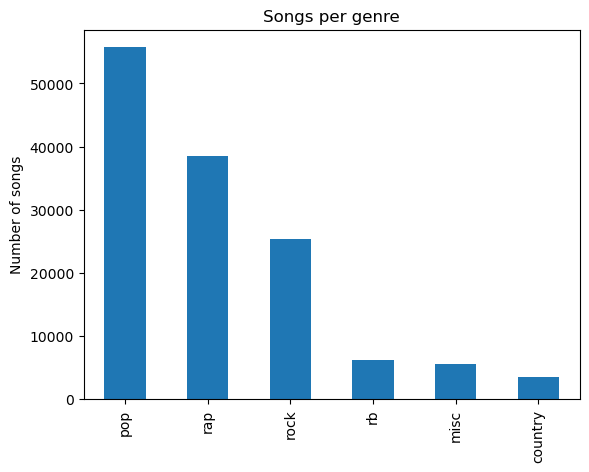

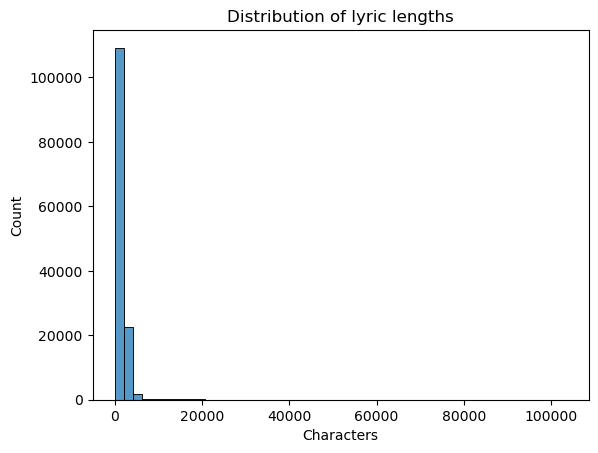

,title,tag,artist,year,views,features,lyrics,id
4,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...,7639050
2352,Parks n Wreck,rap,Joshy Raps,6,54,{},"All the same height, same size, same level but...",2393721
4258,Insecure,pop,Taylor Stannard,69,156,{},(verse one)\n\nI’m not afraid to suck your bal...,7252806
4919,Acts 3,misc,Holy Bible (KJV),1,417,{},Acts 3:1: Now Peter and John went up together ...,113408
5252,King John Act 4 Scene 2,misc,William Shakespeare,1595,75,{},...,155576
...,...,...,...,...,...,...,...,...
133031,Henry VI Part 3 Act 5 Scene 4,misc,William Shakespeare,1591,29,{},SCENE IV. Plains near Teaksbury.\n\nMarch. Ent...,155841
133089,Im Gay,pop,Niggaa,1017,87,"{""Dick Ross & Gay Z"",""Suckdick Cumon!""}",Bitch Im Gay! ft. Jay Z\nYuh im OJ!!!!!! black...,7123550
134531,Every Man out of His Humour Act 1. Scene 1,misc,Ben Jonson,1599,40,{},"The Country.\n\nENTER MACILENTE, WITH A BOOK.\...",671037
134721,Store Cypher,rap,Lil' $erj,1,14,"{""Lil\\' \\$erj""}",(Opening)\nPinned up in Lorbeez\nI just want t...,3074488


In [ ]:
if "tag" in train_df.columns:
    train_df["tag"].value_counts().plot(kind="bar", title="Songs per genre")
    plt.ylabel("Number of songs")
    plt.show()

if "lyrics" in train_df.columns:
    lyric_lengths = train_df["lyrics"].fillna("").str.len()
    sns.histplot(lyric_lengths, bins=50)
    plt.title("Distribution of lyric lengths")
    plt.xlabel("Characters")
    plt.show()

if "year" in train_df.columns:
    years = pd.to_numeric(train_df["year"], errors="coerce")
    display(train_df[(years < 100) | (years > 2026)])

We decided to eliminate every row where the year is lower than 1600, because there are a lot of books and strange years (ex: "1" or "5") that could be musics from the modern days, but is impossible to preserve them beacuse it would require the search of every strange date and impute the real date for each one. The percentage of this rows is no significative to affect the rest of the data. 

In [12]:
# Estimate word counts by splitting text on whitespace
train_df["word_count"] = train_df["lyrics"].str.split().str.len()

# Compare word counts between the two groups
train_df.groupby(train_df["year"] < 1600)["word_count"].describe()

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
False,134858.0,316.873682,444.906423,1.0,158.0,244.0,377.0,18221.0
True,109.0,1233.577982,2601.692360,38.0,180.0,378.0,804.0,18033.0


In [ ]:
train_df["word_count"] = train_df["lyrics"].str.split().str.len()
train_df[(train_df['word_count'] > 1000)]

,title,tag,artist,year,views,features,lyrics,id,word_count
157,Edwin Morris or The Lake,misc,Alfred Lord Tennyson,2013,34,{},"O Me, my pleasant rambles by the lake,\nMy swe...",167715,1188
227,Trial by Fire,rap,Blaze Audio,2017,161,{},"[Intro: Sample ""The Fantastic Four - The Way i...",3910860,1303
314,Zora Neale Hurston’s “Their Eyes Were Watching...,misc,Mr. Allen,2014,39,{},"Long before the year was up, Janie noticed tha...",593806,2302
373,Revolution and Counter-Revolution Or Germany i...,misc,Karl Marx,2013,9,"{""Eleanor Marx Aveling""}","The Late Trial At Cologne\n\nDecember 22, 1852...",174393,2529
807,The Battle of Life Chap. 2,misc,Charles Dickens,1846,23,{},Part The Second\n\nSNITCHEY AND CRAGGS had a s...,160661,11628
...,...,...,...,...,...,...,...,...,...
134835,The Sea-Wolf Chap. 31,misc,Jack London,2016,2,{},"“It will smell,” I said, “but it will keep in ...",164868,1013
134860,Drowning on Dry Land,misc,Grey's Anatomy,2007,15,"{""Grey\\'s Anatomy""}",(Camera focuses on the water. Faces can be see...,5827263,5114
134865,The Faerie Queene Book 6.2,misc,Edmund Spenser,1590,10,{},CANTO II\n\nCalidore sees young Tristram slay\...,156930,3599
134883,SCP-695,misc,The SCP Foundation,2012,7,{},Item #: SCP-695\n\nObject Class: Safe\n\nSpeci...,3175628,1359


Among the texts inspected with more than 1,000 words, most were labelled as rap or misc. The inspected misc entries were predominantly literary works, whereas the rap entries appeared to be song lyrics, pop also has some. This suggests that long texts can reflect genre characteristics rather than data quality issues. Therefore, we do not remove records based solely on word count.

In [20]:
train_df[(train_df['word_count'] < 18)]

,title,tag,artist,year,views,features,lyrics,id,word_count
1477,Salvation Smothered Genocide of Flock,rock,Revenge (CA),2020,142,{},Take down false masters to destroy corrupt cun...,5776081,16
11219,Benign neglect word,misc,Crls 222,2014,4,{},http://blogs.iadb.org/caribbean-dev-trends/fil...,503039,14
13485,Rattlesnake,pop,Ohio Players,2015,81,{},Here it comes\nIt's comin' to getcha\nThe ratt...,1384655,15
14149,Activated part 1 - Origins of a Rap Acrobat,rap,Rebel XD,2015,29,{},This page has been moved to here... http://gen...,659116,8
14995,If His Name Starts With A K,misc,Traditional,2020,3,{},"If his name starts with a ""k""\n\nWe all know h...",6482459,15
22222,Derelictus,rock,Hexis,2017,4,{},"Purge\nTied up, helpless, tied up, hopeless, t...",7267107,16
25537,​the weapon was always there,misc,Adam Showalter,2010,8,{},while the first\n\natomic bomb was\n\nbeing ex...,2954824,17
40176,Jimmy Carter Peanut Farmer,pop,Dani Jochums,2017,43,{},Jimmy Carter\nPeanut Farmer\nFriend of the ext...,3329444,17
52304,On Borrowed Time,misc,3viL,2015,29,{},Listless Atonement...\n\nThoroughly Thawed Thi...,2348530,15
58817,HSC Economic Terms Working Glossary,misc,Patrick Rossey,2016,23,{Mcryn},Debt servicing\nDebt servicing ratio\nDebt Tra...,2428634,17


Despite this examples having only few words we have confirmed and they are songs, there is two one exemple which is the lyrics did not load so we will remove after ("Activated part 1 - Origins of a Rap Acrobat", `title` and "Alison Ritz  Margaret Weisman’s “Minimum Wage Debate Project for Economics for Us Marking Period 2”")

In [21]:
# Compare word count distributions across genres
train_df.groupby("tag")["word_count"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
tag,,,,,,,,
country,3466.0,232.4,160.2,27.0,161.0,217.0,284.0,7092.0
misc,5640.0,974.0,1884.1,1.0,116.0,258.0,828.8,18221.0
pop,55742.0,227.3,127.0,15.0,141.0,205.0,287.0,3775.0
rap,38584.0,436.9,243.0,8.0,288.0,415.0,553.0,9831.0
rb,6203.0,308.5,156.7,19.0,199.0,291.0,394.0,2293.0
rock,25332.0,202.4,105.9,16.0,131.0,188.0,256.0,2246.0


In [33]:
def show_longest_lyrics(df, genre, n):
    """Return the n longest lyrics for a selected genre."""
    genre_df = df[df["tag"] == genre]

    return genre_df[["title", "artist","features","views", "word_count","lyrics"]].sort_values(
        "word_count", ascending=False
    ).head(n)

We have a lot of rap battles! Does this count?

In [35]:
show_longest_lyrics(train_df, "rap", n=15)

,title,artist,features,views,word_count,lyrics
91969,Poet Laureate Infinity,Canibus,{},73992,9831,[Vocal Layer 1: Canibus]\nI got bored with 4 b...
22976,Chapter 2: Variation Under Nature,Charles Darwin,{},350,6546,Variability—Individual differences—Doubtful sp...
63683,Loaded Lux vs. Geechi Gotti,URLtv,"{""Loaded Lux"",""Geechi Gotti""}",10310,6147,[Round 1: Geechi Gotti]\nWe got Geechi Gotti v...
43399,Tierstar Vs. Dizaster,Rap am Mittwoch,"{Dizaster,Tierstar}",3044,5508,[Part 1: Dizaster]\nYou are begging to have a ...
126606,T-Top vs. Eazy The Block Captain,URLtv,"{T-Top,""Eazy The Block Captain""}",284,5478,[Round 1: T-Top]\nI saw dawg\nI don't give a f...
57861,Geechi Gotti vs. Chess,URLtv,"{Chess,""Geechi Gotti""}",3485,5271,"[Round 1: Chess]\nFirst and foremost, bring up..."
25885,Wit Remy vs Yung God Swag,Talk-yo-shit Discord League,{},176,4916,[Yung God Swag]Round 1:\nLast battle you said\...
103857,Arsonal vs. Brizz Rawsteen,URLtv,"{Arsonal,""Brizz Rawsteen""}",3512,4910,"[Round 1: Brizz Rawsteen]\nBrizz vs Ars', it’s..."
45861,WorldWide Choppers Big Remix,Tech N9ne,"{Twista,""Busta Rhymes"",Wrekonize,DRO,""Dino (IT...",81,4639,"[Verse 1: Ceza (Turkey)]\nSen kalk, bir minik ..."
93962,Cage Vast Aire El-P Mr. Lens MySpace comments...,Cage,"{El-P,""Vast Aire"",""Mr. Len""}",2755,4500,Cage\n\n\n\nRemembering Camu Tao\nMay 25th 200...


In [34]:
show_longest_lyrics(train_df, "country", n=30)

,title,artist,features,views,word_count,lyrics
82365,I Know a Song That Will Get on Your Nerves,Mike Duce,{},13,7092,I know a song that will get on your nerves\nGe...
94927,The Ballad of John Axon,Ewan MacColl,{},1734,3158,John Axon was a railway man to steam trains bo...
70896,The Pause of Mr. Claus,Arlo Guthrie,{},2634,1051,[Spoken Introduction]\n\nThis next song we're ...
104765,Can I Get Some Love 2015,Tennessee Shine,{},21,1007,[Chorus]\nCan I get some backwoods? (Hey)\nCan...
49700,Lone Ranger / Faxxx,Randy Savvy,{},32,999,"Part 1: Lone Ranger\n\n(RTG, **** ain't free)\..."
11317,Ride Through The Country,Colt Ford,"{""John Michael Montgomery""}",5331,810,"[Intro: Colt Ford]\nThank y'all, how y'all doi..."
105700,HI-DEAS 10,Upchurch,{},2511,764,[Intro]\nYeah\nChurch\n\n[Verse 1]\nI'm the tr...
117780,Brighton,Mark Lotterman,{},2,751,BRIGHTON\n\nIt's a sunny day in Brighton and a...
132958,Love Yoself,RaskE,{},1,750,She the type to kiss and leave\nI don’t mind t...
95392,Mr. Record Man/Hello Walls/One Day at a Time L...,Willie Nelson,{},149,733,[Intro: Bo Powell & Willie Nelson]\nPanther Ha...
